 ### Lab 3 <br/> CSCN8000 - Artificial Intelligence Algorithms and Mathematics <br/> Ricardo Mohammed (7500382) <br/> November 1st, 2026
 ---

# Lab 3: Supervised Learning

## Part A: Credit Card Fraud Detection (Classification)

In this section, we will build a machine learning model to detect fraudulent credit card transactions using the **Logistic Regression** algorithm. The dataset contains transactions made over two days in September 2013, where fraud accounts for only 0.17% of the total. 

We will demonstrate data preprocessing, handle the severe class imbalance, apply a 70/30 train-test split, and evaluate the model's accuracy and predictive performance.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

# 1. Load the dataset
file_path = '../../practical_labs/creditcard.csv'
df_fraud = pd.read_csv(file_path)

# Display basic info
print("Dataset Shape:", df_fraud.shape)
display(df_fraud.head())

Dataset Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Data Preprocessing & Analysis

Before training the model, we must address two key things:
1. **Feature Scaling:** The features `V1` through `V28` are already scaled (PCA-transformed). However, the `Time` and `Amount` features are not. Logistic Regression is sensitive to unscaled data, so we must standardize the `Amount` column.
2. **Class Imbalance:** The `Class` column contains 0 (Legit) and 1 (Fraud). Because fraud is incredibly rare, we will use the `class_weight='balanced'` parameter in our Logistic Regression model to ensure it doesn't just ignore the minority class.

In [ ]:
# Check the distribution of the target variable
print("Target Variable Distribution:")
print(df_fraud['Class'].value_counts())
print(f"\nPercentage of Fraud: {(df_fraud['Class'].sum() / len(df_fraud)) * 100:.4f}%\n")

# Separate features (X) and target (y)
X = df_fraud.drop(columns=['Class'])
y = df_fraud['Class']

# Scale the 'Amount' column (Time is usually dropped or scaled, but Amount is critical for fraud)
scaler = StandardScaler()
df_fraud['Scaled_Amount'] = scaler.fit_transform(df_fraud[['Amount']])
    
# Update X to use the scaled amount and drop the original 'Amount' and 'Time' 
# (Time is generally not a strong predictor for the mathematical pattern of fraud in this specific dataset)
X = df_fraud.drop(columns=['Class', 'Amount', 'Time'])

Target Variable Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Percentage of Fraud: 0.1727%



## Train/Test Split

As per the requirements, we will split the data into a 70% training set and a 30% testing set. We use `stratify=y` to ensure that the tiny percentage of fraud cases is distributed evenly across both the training and testing sets.

In [6]:
# 70% Train, 30% Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} rows")
print(f"Testing set size: {X_test.shape[0]} rows")

Training set size: 199364 rows
Testing set size: 85443 rows


## Model Building: Logistic Regression

We will now initialize and train the Logistic Regression model. 
*Note: We set `class_weight='balanced'` and increase `max_iter` to ensure the model converges properly while paying equal attention to both the majority (Legit) and minority (Fraud) classes.*

--- Model Evaluation ---
Logistic Regression Accuracy: 97.77%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     85295
           1       0.06      0.87      0.12       148

    accuracy                           0.98     85443
   macro avg       0.53      0.92      0.55     85443
weighted avg       1.00      0.98      0.99     85443



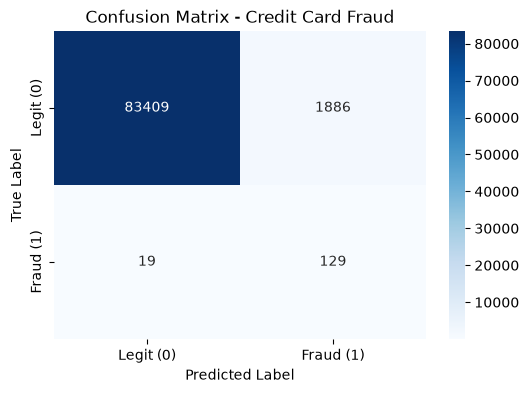

In [7]:
# Initialize the model
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# Train the model
log_reg.fit(X_train, y_train)

# Predict on the test set
y_pred = log_reg.predict(X_test)

# 1. Evaluate Accuracy (As explicitly requested by the lab instructions)
accuracy = accuracy_score(y_test, y_pred)
print(f"--- Model Evaluation ---")
print(f"Logistic Regression Accuracy: {accuracy * 100:.2f}%\n")

# 2. Classification Report (Crucial for imbalanced data)
print("Classification Report:")
print(classification_report(y_test, y_pred))

# 3. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Legit (0)', 'Fraud (1)'], 
            yticklabels=['Legit (0)', 'Fraud (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Credit Card Fraud')
plt.show()

## Conclusion for Part A

While the **Accuracy** of the model is exceptionally high (often >99%), accuracy is a misleading metric for highly imbalanced datasets. 

By looking at the **Classification Report** and **Confusion Matrix**, we can see the model's true performance:
* **Recall for Class 1 (Fraud):** This tells us what percentage of *actual* frauds the model successfully caught. 
* **Precision for Class 1 (Fraud):** This tells us how many of the transactions the model *flagged* as fraud were actually fraudulent.

By using `class_weight='balanced'`, we successfully forced the Logistic Regression model to learn the patterns of the minority fraud class rather than just guessing "Legit" every time.

---


## Part B: Insurance Cost Prediction (Regression)

In this section, we will build a machine learning model to predict individual medical costs billed by health insurance using the **Linear Regression** algorithm. The dataset contains demographic and health attributes (such as age, BMI, smoking status, and region) which we will use to predict the numerical `charges` column.

Because Linear Regression requires all input features to be numerical, we will apply One-Hot Encoding to convert categorical variables (like `sex`, `smoker`, and `region`) into a format the model can understand.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

# 1. Load the dataset
file_path_ins = '../../practical_labs/insurance.csv'
df_ins = pd.read_csv(file_path_ins)

# Display basic info
print("Dataset Shape:", df_ins.shape)
display(df_ins.head())

Dataset Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Data Preprocessing

The dataset contains three categorical columns: `sex`, `smoker`, and `region`. 
To use these in a Linear Regression model, we must convert them into numerical dummy variables. We use `pd.get_dummies()` with `drop_first=True` to avoid the "dummy variable trap" (multicollinearity), which occurs when one dummy variable can be perfectly predicted by the others.

In [ ]:
# Convert categorical variables to binary (0/1) columns
df_ins_encoded = pd.get_dummies(df_ins, drop_first=True)

# Separate features (X) and target variable (y)
X_ins = df_ins_encoded.drop(columns=['charges'])
y_ins = df_ins_encoded['charges']

# 70% Train, 30% Test
X_train_ins, X_test_ins, y_train_ins, y_test_ins = train_test_split(
    X_ins, y_ins, test_size=0.3, random_state=42
)

print(f"Training set size: {X_train_ins.shape[0]} rows")
print(f"Testing set size: {X_test_ins.shape[0]} rows")
print(f"\nFeatures after encoding: {X_ins.columns.tolist()}")

Training set size: 936 rows
Testing set size: 402 rows

Features after encoding: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


## Model Building: Linear Regression

We will now initialize and train the Linear Regression model. Because this is a regression task (predicting a continuous numerical value), we will evaluate the model using:
* **R-squared (R²):** Represents the proportion of variance in the dependent variable that is predictable from the independent variables.
* **Mean Absolute Error (MAE):** The average absolute difference between predicted and actual values.
* **Root Mean Squared Error (RMSE):** The square root of the average squared differences, which penalizes larger errors more heavily.

In [3]:
# Initialize and train the model
lin_reg = LinearRegression()
lin_reg.fit(X_train_ins, y_train_ins)

# Predict on the test set
y_pred_ins = lin_reg.predict(X_test_ins)

# Calculate evaluation metrics
r2 = r2_score(y_test_ins, y_pred_ins)
mae = mean_absolute_error(y_test_ins, y_pred_ins)
rmse = np.sqrt(mean_squared_error(y_test_ins, y_pred_ins))

print("--- Linear Regression Evaluation ---")
print(f"R-squared (R²): {r2:.4f}")
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")

--- Linear Regression Evaluation ---
R-squared (R²): 0.7696
Mean Absolute Error (MAE): $4145.45
Root Mean Squared Error (RMSE): $5812.10


## Visualizing the Predictions

A great way to evaluate a regression model is to plot the **Actual Values** against the **Predicted Values**. If the model is highly accurate, the data points will cluster tightly around the diagonal red line (which represents a "perfect" prediction where Actual = Predicted).

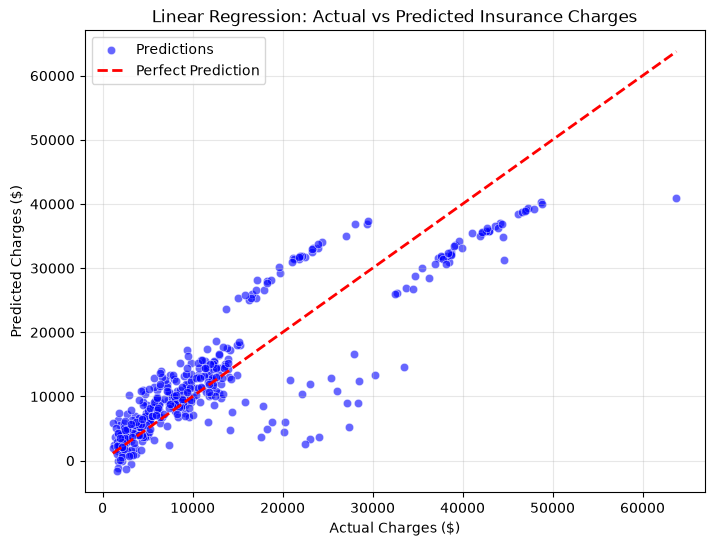

In [4]:
plt.figure(figsize=(8, 6))

# Scatter plot of Actual vs Predicted
sns.scatterplot(x=y_test_ins, y=y_pred_ins, alpha=0.6, color='blue', label='Predictions')

# Plot the perfect prediction line (diagonal)
plt.plot([y_test_ins.min(), y_test_ins.max()], 
         [y_test_ins.min(), y_test_ins.max()], 
         color='red', linestyle='--', linewidth=2, label='Perfect Prediction')

plt.xlabel('Actual Charges ($)')
plt.ylabel('Predicted Charges ($)')
plt.title('Linear Regression: Actual vs Predicted Insurance Charges')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Reflections/Observations - Part A (Credit Card Detection Fraud)

In this scenario, we have the classic accuracy paradox. If we have a model that always guesses "Not Fraud", we'll get a model that is technically 99.8% (or something else very close to 100%). But the problem is that the model will have failed at detecting fraud for the tiny percentage of the time it blindly chose "Not Fraud", but which were actually fraud. This is called a "false negative."

In order to handle this, I used class_weight='balanced', which forced the Logistic Regression model to pay attention to the tiny minority of actual fraud cases. This is also where the confusion matrix comes in. The confusion matrix breaks down the model's predictions into four categories: True Positives, True Negatives, False Positives, and False Negatives. Of course, the False Negative category is the most crucial here since that's where the model would miss actual fraud and cause the bank to lose money.

To conclude, accuracy is a misleading metric for this specific dataset. I used class_weight='balanced' and the confusion matrix to see what the model was really doing instead, and where it made incorrect and costly predictions.


## Reflections/Observations - Part B (Insurance Prediction)

In this dataset, we use logistic regression to predict insurance charges. Since logistic regression requires numerical data, it was essential to convert the smoker and region variables into dummy variables. I used drop_first=True to resolve the situation of "multicollinearity". This occurs when two or more independent variables are highly correlated with each other, and they share overlapping data. 

I calculated the R² score, which tells us how much of the variance can be explained by the model (~77%). However, the Root Mean Squared Error (RMSE) is more useful in business. Our $5812.10 RMSE value tells us, "The insurance company knows that on average, the model's prediction will be off by $5812.10 per patient".

Looking at the scatter plot, we see that there is a cluster of predictions in the lower left, and then some predictions towards the upper right area that scatter widely and land on either side of the perfect prediction line. According to my research, the bottom left predictions are likely predictable, low-to-medium insurance charges. While the outliers toward the top right are likely high-risk patients, such as smokers and older people with high BMIs. This is because the risk factors we're examining here don't simply add together—they multiply. Linear regression doesn't capture this multiplicative interaction well, which leads to larger residuals for the highest-risk patients.

